In [1]:
import os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef)

SEED = 42


In [2]:
cols = [
    "Elevation",
    "Aspect",
    "Slope",
    "Horiz_Dist_Hydrology",
    "Vert_Dist_Hydrology",
    "Horiz_Dist_Roadways",
    "Hillshade_9am",
    "Hillshade_Noon",
    "Hillshade_3pm",
    "Horiz_Dist_FirePoints",
]
cols += [f"Wilderness_Area{i}" for i in range(1, 5)]
cols += [f"Soil_Type{i}" for i in range(1, 41)]

cols += ["Cover_Type"]

df = pd.read_csv("../covtype.data", header=None, names=cols)
print(df.shape)
df.head()

(581012, 55)


,Elevation,Aspect,Slope,Horiz_Dist_Hydrology,Vert_Dist_Hydrology,Horiz_Dist_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horiz_Dist_FirePoints,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


In [3]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Missing values: 0
Duplicate rows: 0
Shape after removing duplicates: (581012, 55)


Cover_Type
1    211840
2    283301
3     35754
4      2747
5      9493
6     17367
7     20510
Name: count, dtype: int64


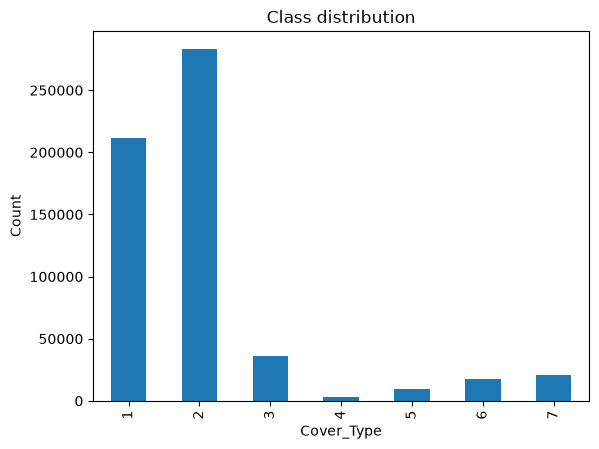

In [4]:
print(df["Cover_Type"].value_counts().sort_index())
df["Cover_Type"].value_counts().sort_index().plot(kind="bar")
plt.title("Class distribution"); plt.xlabel("Cover_Type"); plt.ylabel("Count")
plt.show()

In [5]:
df_small, _ = train_test_split(df, train_size=50000,
                               stratify=df["Cover_Type"], random_state=SEED)
print(df_small.shape)
print(df_small["Cover_Type"].value_counts(normalize=True).sort_index())

(50000, 55)
Cover_Type
1    0.36460
2    0.48760
3    0.06154
4    0.00472
5    0.01634
6    0.02990
7    0.03530
Name: proportion, dtype: float64


In [6]:
df_small, _ = train_test_split(df, train_size=50000,
                               stratify=df["Cover_Type"], random_state=SEED)
print(df_small.shape)
print(df_small["Cover_Type"].value_counts(normalize=True).sort_index())

(50000, 55)
Cover_Type
1    0.36460
2    0.48760
3    0.06154
4    0.00472
5    0.01634
6    0.02990
7    0.03530
Name: proportion, dtype: float64


In [7]:
X = df_small.drop(columns="Cover_Type")
y = df_small["Cover_Type"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape)

test_df = X_test.copy()
test_df["Cover_Type"] = y_test
test_df.to_csv("test_data.csv", index=False)

(40000, 54) (10000, 54)


In [8]:
num_cols = cols[:10]
scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])
print("Scaling done")

Scaling done


In [9]:


models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "Random Forest (Ensemble)": RandomForestClassifier(n_estimators=30, random_state=SEED, n_jobs=-1),
}

results = []
for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    proba = model.predict_proba(X_test_s)
    results.append({
        "ML Model Name": name,
        "Accuracy": accuracy_score(y_test, pred),
        "AUC": roc_auc_score(y_test, proba, multi_class="ovr", average="weighted"),
        "Precision": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall":recall_score(y_test, pred, average="weighted"),
        "F1":  f1_score(y_test, pred, average="weighted"),
        "MCC":  matthews_corrcoef(y_test, pred),
    })
    print(name, "done")

results_df = pd.DataFrame(results).round(4)
results_df

Logistic Regression done
Decision Tree done
kNN done
Naive Bayes done
Random Forest (Ensemble) done


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.7271,0.8728,0.7184,0.7271,0.7158,0.5528
1,Decision Tree,0.8112,0.8472,0.8112,0.8112,0.8112,0.6969
2,kNN,0.8316,0.9392,0.8299,0.8316,0.8298,0.7274
3,Naive Bayes,0.0936,0.6819,0.4322,0.0936,0.0576,0.0623
4,Random Forest (Ensemble),0.8702,0.9633,0.8710,0.8702,0.8680,0.7893


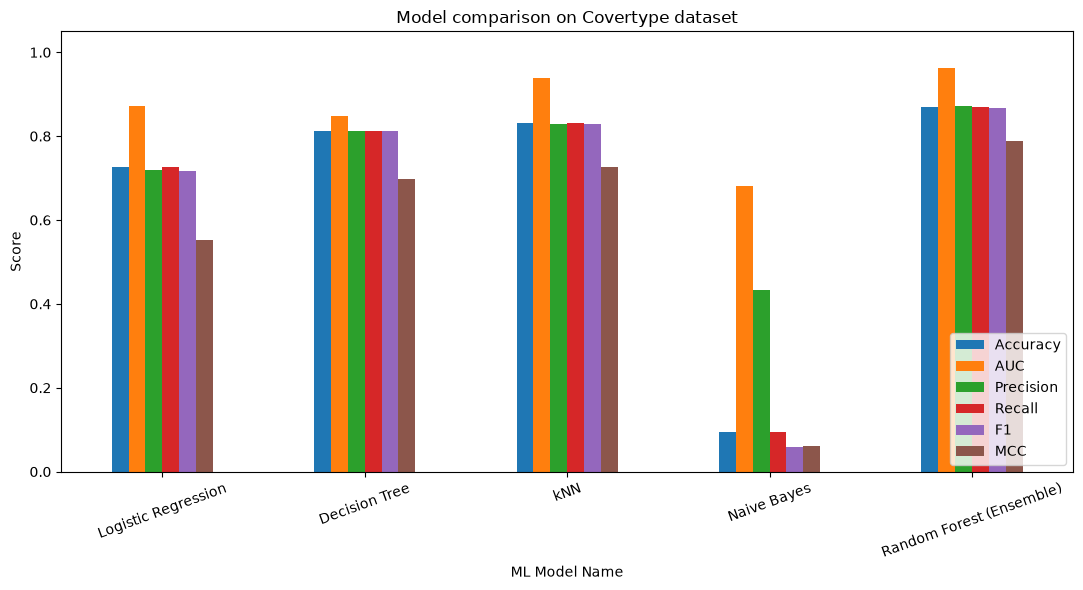

In [10]:
results_df.set_index("ML Model Name").plot(kind="bar", figsize=(11,6))
plt.title("Model comparison on Covertype dataset")
plt.ylabel("Score"); plt.ylim(0, 1.05)
plt.xticks(rotation=20); plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("metrics_comparison.png", dpi=150)
plt.show()

In [11]:
os.makedirs("model", exist_ok=True)
for name, model in models.items():
    fname = name.split(" (")[0].lower().replace(" ", "_")
    joblib.dump(model, f"model/{fname}.pkl", compress=3)
joblib.dump(scaler, "model/scaler.pkl", compress=3)

results_df.to_csv("results.csv", index=False)

with open("requirements.txt", "w") as f:
    f.write("scikit-learn\nnumpy\npandas\nmatplotlib\nseaborn\njoblib\n")

print("Saved files:", os.listdir("model"))

Saved files: ['decision_tree.pkl', 'knn.pkl', 'logistic_regression.pkl', 'naive_bayes.pkl', 'random_forest.pkl', 'scaler.pkl']


In [12]:
import os

files = [
    "test_data.csv",
    "results.csv",
    "metrics_comparison.png",
    "requirements.txt",
]

for f in sorted(os.listdir("model")):
  files.append(f"model/{f}")

for f in files:
  size_mb = os.path.getsize(f) / (1024 * 1024)
  print(f"{f}: {size_mb:.2f} MB")

test_data.csv: 1.24 MB
results.csv: 0.00 MB
metrics_comparison.png: 0.05 MB
requirements.txt: 0.00 MB
model/decision_tree.pkl: 0.18 MB
model/knn.pkl: 2.51 MB
model/logistic_regression.pkl: 0.00 MB
model/naive_bayes.pkl: 0.00 MB
model/random_forest.pkl: 6.84 MB
model/scaler.pkl: 0.00 MB


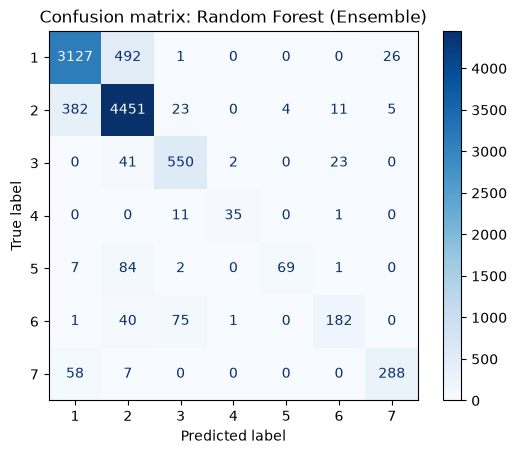

In [13]:


best = results_df.sort_values("MCC", ascending=False).iloc[0]["ML Model Name"]

ConfusionMatrixDisplay.from_estimator(models[best], X_test_s, y_test, cmap="Blues")

plt.title(f"Confusion matrix: {best}")

plt.show()

In [14]:
results_df

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.7271,0.8728,0.7184,0.7271,0.7158,0.5528
1,Decision Tree,0.8112,0.8472,0.8112,0.8112,0.8112,0.6969
2,kNN,0.8316,0.9392,0.8299,0.8316,0.8298,0.7274
3,Naive Bayes,0.0936,0.6819,0.4322,0.0936,0.0576,0.0623
4,Random Forest (Ensemble),0.8702,0.9633,0.8710,0.8702,0.8680,0.7893


In [15]:
pd.read_csv("results.csv")

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.7271,0.8728,0.7184,0.7271,0.7158,0.5528
1,Decision Tree,0.8112,0.8472,0.8112,0.8112,0.8112,0.6969
2,kNN,0.8316,0.9392,0.8299,0.8316,0.8298,0.7274
3,Naive Bayes,0.0936,0.6819,0.4322,0.0936,0.0576,0.0623
4,Random Forest (Ensemble),0.8702,0.9633,0.8710,0.8702,0.8680,0.7893


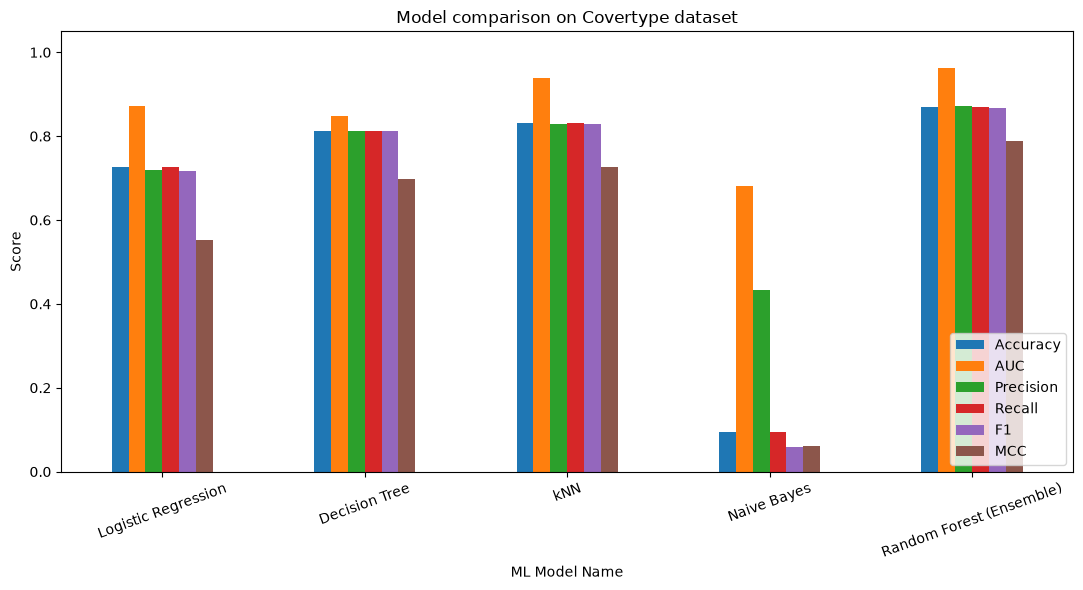

In [16]:
results_df.set_index("ML Model Name").plot(kind="bar", figsize=(11,6))
plt.title("Model comparison on Covertype dataset")
plt.ylabel("Score"); plt.ylim(0, 1.05)
plt.xticks(rotation=20); plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("metrics_comparison.png", dpi=150)
plt.show()

In [17]:
print(pd.Series(models["Naive Bayes"].predict(X_test_s)).value_counts().sort_index())

1     578
2      74
3     817
4     609
5    2246
6     527
7    5149
Name: count, dtype: int64
